**1. Entorno, auditoría y archivos protegidos**

Se revisan el notebook 07, sus resultados y la auditoría antes de definir las mejoras. Solo se escriben el notebook 08 y reportes nuevos; las entradas y resultados anteriores se protegen con hashes.

In [1]:
from pathlib import Path
from datetime import datetime,timezone
import hashlib,json,platform,sys
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import BaseEstimator,TransformerMixin,clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error,root_mean_squared_error,r2_score
ROOT=Path.cwd().resolve()
if ROOT.name=="notebooks":ROOT=ROOT.parent
assert Path(sys.prefix).name=="tesis-fcl"
NB=ROOT/"notebooks/08_mejoras_baseline.ipynb"
OUT=ROOT/"reports/sprint_06/mejoras";OUT.mkdir(parents=True,exist_ok=True)
previos=[ROOT/"README.md",*sorted(p for carpeta in ["data","reports","notebooks","src"] for p in (ROOT/carpeta).rglob("*")
    if p.is_file() and p!=NB and OUT not in p.parents and "__pycache__" not in p.parts and ".ipynb_checkpoints" not in p.parts)]
def hashes_previos():return {str(p.relative_to(ROOT)):hashlib.sha256(p.read_bytes()).hexdigest() for p in previos}
hashes_antes=hashes_previos()
AUDIT=ROOT/"reports/sprint_06/auditoria_baseline_variantes.md"
texto_auditoria=AUDIT.read_text(encoding="utf-8")
nb07=json.loads((ROOT/"notebooks/07_baseline_variantes.ipynb").read_text())
v07=json.loads((ROOT/"reports/sprint_06/validacion_baseline.json").read_text())
resultados07=pd.read_csv(ROOT/"reports/sprint_06/resultados_experimentos.csv",float_precision="round_trip")
pred07=pd.read_csv(ROOT/"reports/sprint_06/predicciones_baseline.csv",dtype={"RPJ":"string","RUC":"string"},float_precision="round_trip")
assert len(nb07["cells"])==51
for nombre,info in v07["inventario"].items():
    assert hashlib.sha256((ROOT/"reports/sprint_06"/nombre).read_bytes()).hexdigest()==info["sha256"]
SEED=42;np.random.seed(SEED)
ALPHAS=[.1,1.,10.,100.,1000.,10000.]
Q_INF,Q_SUP=.01,.99
etapas=[];interpretaciones={}
versiones={p:metadata.version(p) for p in ["pandas","numpy","scikit-learn","matplotlib","nbformat","nbclient"]}
plt.rcParams.update({"axes.grid":True,"grid.alpha":.25})
print("Auditoria revisada:",AUDIT.relative_to(ROOT),"| Grilla alpha predefinida:",ALPHAS)
display(pd.Series(versiones,name="version").to_frame())
interpretaciones[1]="La auditoria orienta cambios de especificacion, pero las cifras y hashes se verifican contra los archivos reales. Alpha y clipping quedan definidos antes de evaluar prueba."
etapas.append(1)

Auditoria revisada: reports/sprint_06/auditoria_baseline_variantes.md | Grilla alpha predefinida: [0.1, 1.0, 10.0, 100.0, 1000.0, 10000.0]


,version
pandas,3.0.6
numpy,2.5.4
scikit-learn,1.9.1
matplotlib,3.11.2
nbformat,5.11.1
nbclient,0.11.0


La auditoria orienta cambios de especificacion, pero las cifras y hashes se verifican contra los archivos reales. Alpha y clipping quedan definidos antes de evaluar prueba.

**2. Muestra y clasificación bancaria**

Se conservan los 3.560 casos elegibles y sus particiones. BANCOS se separa por su etiqueta de origen; no bancario significa no BANCOS e incluye seguros, financieras y AFP, sin excluirlos.

In [2]:
datos=pd.read_csv(ROOT/"data/processed/panel_financiero_macro_bursatil.csv",dtype={"RPJ":"string","RUC":"string"},float_precision="round_trip")
assert datos.shape==(4221,68) and datos.RPJ.nunique()==336
muestra=datos.loc[datos.utilizable_supervisado].copy();muestra["id_fila"]=muestra.index
assert len(muestra)==3560 and muestra.RPJ.nunique()==309
assert muestra.objetivo_fcl_t1.notna().all() and muestra.Moneda.eq(muestra.moneda_objetivo).all()
assert muestra.anio_objetivo.eq(muestra.Ejercicio+1).all()
assert not muestra.duplicated(["RPJ","Ejercicio"]).any()
assert muestra.particion.value_counts().to_dict()=={"entrenamiento":2869,"prueba":691}
muestra["grupo_bancario"]=np.where(muestra.TipoSector.eq("BANCOS"),"bancario","no_bancario")
monedas=sorted(muestra.Moneda.unique())
base07=pred07.loc[pred07.escenario.eq("principal")&pred07.experimento.eq("E0_financiero")].sort_values("id_fila")
a=muestra.sort_values("id_fila")
pd.testing.assert_frame_equal(a[["id_fila","RPJ","RUC","Ejercicio","anio_objetivo"]].reset_index(drop=True),base07[["id_fila","RPJ","RUC","Ejercicio","anio_objetivo"]].reset_index(drop=True),check_dtype=False)
np.testing.assert_array_equal(a.objetivo_fcl_t1,base07.y_real)
np.testing.assert_array_equal(a.particion,base07.particion)
conteos=muestra.groupby(["Moneda","grupo_bancario","particion"]).agg(n=("RPJ","size"),empresas=("RPJ","nunique"),inicio=("anio_objetivo","min"),fin=("anio_objetivo","max"))
display(conteos)
interpretaciones[2]="La prueba conserva 691 filas: 82 bancarias en soles, 517 no bancarias en soles y 92 no bancarias en dolares. No se retiran los casos extremos identificados en la auditoria."
etapas.append(2)

n  empresas  inicio   fin
Moneda  grupo_bancario particion                                  
D lares no_bancario    entrenamiento   353        49    2006  2021
                       prueba           92        26    2022  2025
Soles   bancario       entrenamiento   172        23    2013  2021
                       prueba           82        22    2022  2025
        no_bancario    entrenamiento  2344       246    2006  2021
                       prueba          517       139    2022  2025

La prueba conserva 691 filas: 82 bancarias en soles, 517 no bancarias en soles y 92 no bancarias en dolares. No se retiran los casos extremos identificados en la auditoria.

**3. FCL actual, FCO y disponibilidad temporal**

Se reconstruye FCL(t) como FCO(t) + CAPEX(t), invalidando CAPEX positivo como en el objetivo. Su fecha de publicación no está acreditada: los modelos con niveles t y la persistencia son condicionales a conocer esos estados.

In [3]:
muestra["FCL_t_verificado"]= (muestra.FCO+muestra.CAPEX_reportado).where(~muestra.CAPEX_reportado.gt(0))
muestra["FCO_t"]=muestra.FCO
np.testing.assert_allclose(muestra.FCL_t_verificado,muestra.FCL_preliminar.where(~muestra.CAPEX_reportado.gt(0)),rtol=0,atol=0,equal_nan=True)
futura=datos[["RPJ","Ejercicio","FCO","CAPEX_reportado","Moneda"]].copy()
futura["y"]=(futura.FCO+futura.CAPEX_reportado).where(~futura.CAPEX_reportado.gt(0));futura["Ejercicio"]-=1
contraste=muestra[["RPJ","Ejercicio"]].merge(futura[["RPJ","Ejercicio","y","Moneda"]],on=["RPJ","Ejercicio"],how="left",validate="one_to_one")
np.testing.assert_array_equal(muestra.objetivo_fcl_t1,contraste.y)
np.testing.assert_array_equal(muestra.Moneda,contraste.Moneda)
print("FCL(t) no valido o ausente:",int(muestra.FCL_t_verificado.isna().sum()),"| FCO(t) ausente:",int(muestra.FCO_t.isna().sum()))
print("Disponibilidad real en fecha de pronostico: NO_VERIFICADA; no basta que el año sea t.")
interpretaciones[3]=f"Se verifican algebraicamente los niveles t y el objetivo t+1; {int(muestra.FCL_t_verificado.isna().sum())} casos carecen de FCL(t) valido y se conservan. La fecha de publicacion sigue no verificada."
etapas.append(3)

FCL(t) no valido o ausente: 104 | FCO(t) ausente: 51
Disponibilidad real en fecha de pronostico: NO_VERIFICADA; no basta que el año sea t.


Se verifican algebraicamente los niveles t y el objetivo t+1; 104 casos carecen de FCL(t) valido y se conservan. La fecha de publicacion sigue no verificada.

**4. Especificaciones y cohortes predefinidas**

Se comparan bloques financieros, macro y bursátiles con niveles t, externos t−1 y una sensibilidad sin niveles t. Se ajustan modelos agrupados y sectoriales, sin decidir estas especificaciones por las nuevas métricas de prueba.

In [4]:
FIN19=v07["experimentos"]["E0_financiero"]
MACRO=["inflacion_lima_dic_dic_pct","tipo_cambio_promedio_soles_usd","tasa_referencia_promedio_pct","crecimiento_pbi_real_pct"]
BOLSA=["rentabilidad_indice_anual_pct","volatilidad_diaria_anualizada_pct","monto_renta_variable_anual_millones_pen"]
EXTERNAS=MACRO+BOLSA
NIVELES=["FCL_t_verificado","FCO_t"]
RATIOS=[x for x in FIN19 if "_lag" not in x and "_std3_" not in x]
assert len(FIN19)==19 and len(RATIOS)==11
cat=pd.read_csv(ROOT/"reports/diccionario_integracion_bursatil.csv")
assert cat.set_index("variable").loc[FIN19+EXTERNAS,"predictor_candidato"].all()
ma=pd.read_csv(ROOT/"data/processed/macroeconomia_peru_2005_2025.csv",float_precision="round_trip")
ba=pd.read_csv(ROOT/"data/processed/bursatil_mercado_anual.csv",float_precision="round_trip")
anual=ma[["anio",*MACRO]].merge(ba[["anio",*BOLSA]],on="anio",validate="one_to_one").set_index("anio")
lag=muestra.copy()
for v in EXTERNAS:
    lag[v]=lag.Ejercicio.sub(1).map(anual[v])
    pd.testing.assert_series_equal(lag[v],muestra.Ejercicio.sub(1).map(anual[v]).rename(v),check_exact=True)
TABLAS={"niveles_t_externos_t":muestra,"niveles_t_externos_t_1":lag,"sin_niveles_t_externos_t_1":lag}
CONFIGS={}
for spec in TABLAS:
    financiero=FIN19+NIVELES if not spec.startswith("sin_niveles") else FIN19
    for exp,extra in [("E0_financiero",[]),("E1_macroeconomico",MACRO),("E2_bursatil",EXTERNAS)]:
        CONFIGS[(spec,exp)]=financiero+extra
for cols in CONFIGS.values():assert not {"anio_objetivo","objetivo_fcl_t1","particion","grupo_bancario"}.intersection(cols)
def subconjunto(tabla,moneda,grupo):
    mascara=tabla.Moneda.eq(moneda)
    if grupo!="todas":mascara &= tabla.grupo_bancario.eq(grupo)
    return tabla.loc[mascara].copy()
cohortes=[]
for moneda in monedas:
    for grupo in ["todas","bancario","no_bancario"]:
        t=subconjunto(muestra,moneda,grupo)
        if len(t)>0:
            assert t.particion.eq("entrenamiento").any()
            cohortes.append((moneda,grupo))
print("Cohortes:",cohortes)
display(pd.DataFrame([{"especificacion":s,"experimento":e,"predictores":len(c)} for (s,e),c in CONFIGS.items()]))
interpretaciones[4]="Se predefinen cinco cohortes por moneda/grupo y nueve especificaciones por cohorte. Los niveles t son condicionales; la sensibilidad sin niveles t mantiene 19/23/26 predictores y externos del año anterior."
etapas.append(4)

Cohortes: [('D lares', 'todas'), ('D lares', 'no_bancario'), ('Soles', 'todas'), ('Soles', 'bancario'), ('Soles', 'no_bancario')]


,especificacion,experimento,predictores
0,niveles_t_externos_t,E0_financiero,21
1,niveles_t_externos_t,E1_macroeconomico,25
2,niveles_t_externos_t,E2_bursatil,28
3,niveles_t_externos_t_1,E0_financiero,21
4,niveles_t_externos_t_1,E1_macroeconomico,25
5,niveles_t_externos_t_1,E2_bursatil,28
6,sin_niveles_t_externos_t_1,E0_financiero,19
7,sin_niveles_t_externos_t_1,E1_macroeconomico,23
8,sin_niveles_t_externos_t_1,E2_bursatil,26


Se predefinen cinco cohortes por moneda/grupo y nueve especificaciones por cohorte. Los niveles t son condicionales; la sensibilidad sin niveles t mantiene 19/23/26 predictores y externos del año anterior.

**5. Clipping de ratios dentro del Pipeline**

Los percentiles 1 % y 99 % se aprenden después de imputar, solo con el entrenamiento de cada pliegue. Se acotan únicamente 11 ratios y variaciones; nunca el objetivo, los niveles de FCL/FCO o los indicadores externos.

In [5]:
class ClipRatios(BaseEstimator,TransformerMixin):
    def __init__(self,feature_names,ratio_names,q_low=.01,q_high=.99):
        self.feature_names=feature_names;self.ratio_names=ratio_names;self.q_low=q_low;self.q_high=q_high
    def fit(self,X,y=None):
        z=np.asarray(X,dtype=float)
        self.n_fit_=len(z)
        self.indices_=np.array([i for i,c in enumerate(self.feature_names) if c in self.ratio_names],dtype=int)
        self.lower_=np.quantile(z[:,self.indices_],self.q_low,axis=0)
        self.upper_=np.quantile(z[:,self.indices_],self.q_high,axis=0)
        return self
    def transform(self,X):
        z=np.array(X,dtype=float,copy=True)
        z[:,self.indices_]=np.clip(z[:,self.indices_],self.lower_,self.upper_)
        return z

def modelo(cols,alpha):
    numericas=Pipeline([("imputer",SimpleImputer(strategy="median",keep_empty_features=True)),
        ("clip",ClipRatios(cols,RATIOS,Q_INF,Q_SUP)),("scaler",StandardScaler())])
    pre=ColumnTransformer([("numericas",numericas,cols)],remainder="drop",verbose_feature_names_out=False)
    return Pipeline([("pre",pre),("ridge",Ridge(alpha=alpha,solver="svd"))])

def verificar_transformaciones(pipe,tr,cols):
    prep=pipe.named_steps["pre"].named_transformers_["numericas"]
    imp,clip,scaler=[prep.named_steps[x] for x in ["imputer","clip","scaler"]]
    np.testing.assert_allclose(imp.statistics_,tr[cols].median().fillna(0),rtol=1e-12)
    z=imp.transform(tr[cols]);assert clip.n_fit_==len(tr)
    np.testing.assert_allclose(clip.lower_,np.quantile(z[:,clip.indices_],Q_INF,axis=0),rtol=1e-12)
    np.testing.assert_allclose(clip.upper_,np.quantile(z[:,clip.indices_],Q_SUP,axis=0),rtol=1e-12)
    w=clip.transform(z)
    fuera=[i for i in range(len(cols)) if i not in clip.indices_]
    np.testing.assert_array_equal(w[:,fuera],z[:,fuera])
    np.testing.assert_allclose(scaler.mean_,w.mean(axis=0),rtol=1e-12,atol=1e-12)
    assert int(scaler.n_samples_seen_)==len(tr)
    return prep
print("Clipping fijo:",Q_INF,Q_SUP,"| Variables:",RATIOS)
interpretaciones[5]="Solo los 11 ratios y variaciones reciben clipping; los cuantiles se verifican en cada fold y ajuste final. Las filas, objetivos y niveles monetarios se conservan."
etapas.append(5)

Clipping fijo: 0.01 0.99 | Variables: ['pasivo_activo', 'margen_neto', 'rentabilidad_activo_cierre', 'rotacion_activo_cierre', 'fco_activo', 'fco_ingresos', 'inversion_capex_activo', 'crecimiento_ActivoTotal', 'crecimiento_TotalIngreso', 'cambio_FCO_activo_previo', 'cambio_FCL_preliminar_activo_previo']


Solo los 11 ratios y variaciones reciben clipping; los cuantiles se verifican en cada fold y ajuste final. Las filas, objetivos y niveles monetarios se conservan.

**6. Pliegues temporales por años únicos**

La validación usa ventanas expansivas con bloques de dos años objetivo: ocho años iniciales en cohortes completas y cinco en banca. Todas las empresas de un año quedan en el mismo bloque; ninguna fila de prueba entra en la búsqueda de alpha.

In [6]:
pliegues={};plan=[]
for moneda,grupo in cohortes:
    tr=subconjunto(muestra,moneda,grupo).query("particion=='entrenamiento'")
    years=sorted(tr.anio_objetivo.unique())
    assert len(years)>=6
    warmup=8 if len(years)>=12 else max(4,len(years)-4)
    folds=[]
    for inicio in range(warmup,len(years),2):
        valyears=years[inicio:inicio+2];trainyears=years[:inicio]
        a=tr.index[tr.anio_objetivo.isin(trainyears)].tolist();b=tr.index[tr.anio_objetivo.isin(valyears)].tolist()
        assert a and b and max(tr.loc[a,"anio_objetivo"])<min(tr.loc[b,"anio_objetivo"])
        assert not set(a).intersection(b)
        assert tr.loc[a+b,"particion"].eq("entrenamiento").all()
        folds.append((a,b))
        plan.append({"moneda":moneda,"grupo":grupo,"fold":len(folds),"anios_train":[int(y) for y in trainyears],
            "anios_validacion":[int(y) for y in valyears],"n_train":len(a),"n_validacion":len(b),"ids_train":a,"ids_validacion":b})
    pliegues[(moneda,grupo)]=folds
plan_df=pd.DataFrame(plan)
display(plan_df.drop(columns=["ids_train","ids_validacion"]))
print("Criterio de seleccion: media de MSE por año de validacion; cada año recibe el mismo peso.")
interpretaciones[6]="BANCOS tiene nueve años de entrenamiento y dos folds (2018–2021); las otras cohortes tienen 16 años y cuatro folds (2014–2021). Ninguna validacion utiliza prueba 2022–2025."
etapas.append(6)

,moneda,grupo,fold,anios_train,anios_validacion,n_train,n_validacion
0,D lares,todas,1,"[2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013]","[2014, 2015]",154,54
1,D lares,todas,2,"[2006, 2007, 2008, 2009, 2010, 2011, 2012, 201...","[2016, 2017]",208,47
2,D lares,todas,3,"[2006, 2007, 2008, 2009, 2010, 2011, 2012, 201...","[2018, 2019]",255,51
3,D lares,todas,4,"[2006, 2007, 2008, 2009, 2010, 2011, 2012, 201...","[2020, 2021]",306,47
4,D lares,no_bancario,1,"[2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013]","[2014, 2015]",154,54
5,D lares,no_bancario,2,"[2006, 2007, 2008, 2009, 2010, 2011, 2012, 201...","[2016, 2017]",208,47
6,D lares,no_bancario,3,"[2006, 2007, 2008, 2009, 2010, 2011, 2012, 201...","[2018, 2019]",255,51
7,D lares,no_bancario,4,"[2006, 2007, 2008, 2009, 2010, 2011, 2012, 201...","[2020, 2021]",306,47
8,Soles,todas,1,"[2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013]","[2014, 2015]",1155,357
9,Soles,todas,2,"[2006, 2007, 2008, 2009, 2010, 2011, 2012, 201...","[2016, 2017]",1512,352


Criterio de seleccion: media de MSE por año de validacion; cada año recibe el mismo peso.


BANCOS tiene nueve años de entrenamiento y dos folds (2018–2021); las otras cohortes tienen 16 años y cuatro folds (2014–2021). Ninguna validacion utiliza prueba 2022–2025.

**7. Selección de alpha sin utilizar prueba**

Se evalúan seis valores de alpha por configuración con las mismas ventanas temporales. El error se agrega por año, no por número de empresas, y los desempates favorecen mayor regularización.

In [7]:
cv=[];cv_anios=[]
for moneda,grupo in cohortes:
    for (spec,exp),cols in CONFIGS.items():
        tabla=TABLAS[spec]
        for fold,(idx_tr,idx_va) in enumerate(pliegues[(moneda,grupo)],1):
            tr,va=tabla.loc[idx_tr],tabla.loc[idx_va]
            # El preprocesador no depende de alpha: se ajusta una vez dentro de este fold.
            temp=modelo(cols,1.)
            ztr=temp.named_steps["pre"].fit_transform(tr[cols],tr.objetivo_fcl_t1)
            verificar_transformaciones(temp,tr,cols)
            zva=temp.named_steps["pre"].transform(va[cols])
            for alpha in ALPHAS:
                ridge=Ridge(alpha=alpha,solver="svd").fit(ztr,tr.objetivo_fcl_t1)
                p=ridge.predict(zva);assert np.isfinite(p).all()
                e=pd.DataFrame({"anio":va.anio_objetivo.to_numpy(),"sq":(p-va.objetivo_fcl_t1.to_numpy())**2})
                mse_anual=e.groupby("anio").sq.mean()
                cv.append({"moneda":moneda,"grupo":grupo,"especificacion":spec,"experimento":exp,"alpha":alpha,"fold":fold,
                    "mse_anual_medio":float(mse_anual.mean()),"n_train":len(tr),"n_validacion":len(va)})
                for y,s in mse_anual.items():cv_anios.append({"moneda":moneda,"grupo":grupo,"especificacion":spec,"experimento":exp,"alpha":alpha,"fold":fold,"anio_validacion":int(y),"mse":float(s)})
        print("CV completada:",moneda,grupo,spec,exp,flush=True)
cv=pd.DataFrame(cv);cv_anios=pd.DataFrame(cv_anios)
puntuaciones=cv_anios.groupby(["moneda","grupo","especificacion","experimento","alpha"],as_index=False).mse.mean().rename(columns={"mse":"mse_cv"})
puntuaciones["rmse_cv"]=np.sqrt(puntuaciones.mse_cv)
optimos=puntuaciones.sort_values(["mse_cv","alpha"],ascending=[True,False],kind="stable").drop_duplicates(["moneda","grupo","especificacion","experimento"]).copy()
assert len(optimos)==len(cohortes)*len(CONFIGS)
# Una configuracion final por cohorte se decide aqui, antes de generar nuevas predicciones de prueba.
ganadores=optimos.sort_values(["mse_cv","alpha","especificacion","experimento"],ascending=[True,False,True,True],kind="stable").drop_duplicates(["moneda","grupo"])
seleccion_congelada=ganadores[["moneda","grupo","especificacion","experimento","alpha","rmse_cv"]].copy()
hash_seleccion=hashlib.sha256(seleccion_congelada.to_csv(index=False).encode()).hexdigest()
display(seleccion_congelada)
interpretaciones[7]="Ganadores sectoriales CV: " + "; ".join(f"{r.moneda}/{r.grupo}: {r.experimento}, alpha {r.alpha:g}" for r in seleccion_congelada.loc[seleccion_congelada.grupo.ne('todas')].itertuples()) + ". No se selecciona por prueba."
etapas.append(7)

CV completada: D lares todas niveles_t_externos_t E0_financiero


CV completada: D lares todas niveles_t_externos_t E1_macroeconomico


CV completada: D lares todas niveles_t_externos_t E2_bursatil


CV completada: D lares todas niveles_t_externos_t_1 E0_financiero


CV completada: D lares todas niveles_t_externos_t_1 E1_macroeconomico


...

CV completada: Soles no_bancario niveles_t_externos_t_1 E2_bursatil


CV completada: Soles no_bancario sin_niveles_t_externos_t_1 E0_financiero


CV completada: Soles no_bancario sin_niveles_t_externos_t_1 E1_macroeconomico


CV completada: Soles no_bancario sin_niveles_t_externos_t_1 E2_bursatil


,moneda,grupo,especificacion,experimento,alpha,rmse_cv
28,D lares,no_bancario,niveles_t_externos_t_1,E1_macroeconomico,1000.0,2.704516e+05
82,D lares,todas,niveles_t_externos_t_1,E1_macroeconomico,1000.0,2.704516e+05
214,Soles,no_bancario,sin_niveles_t_externos_t_1,E2_bursatil,1000.0,3.384358e+05
224,Soles,todas,niveles_t_externos_t,E1_macroeconomico,10.0,8.446541e+05
134,Soles,bancario,niveles_t_externos_t_1,E1_macroeconomico,10.0,2.886677e+06


Ganadores sectoriales CV: D lares/no_bancario: E1_macroeconomico, alpha 1000; Soles/no_bancario: E2_bursatil, alpha 1000; Soles/bancario: E1_macroeconomico, alpha 10. No se selecciona por prueba.

**8. Baselines ingenuos de media y persistencia**

La media se aprende con el objetivo de entrenamiento de cada cohorte. La persistencia usa FCL(t) válido; si falta, emplea la mediana del FCL(t) de entrenamiento, conservando todas las filas y documentando esa sustitución.

In [8]:
referencias={};naive_filas=[];param_naive=[]
for moneda,grupo in cohortes:
    t=subconjunto(muestra,moneda,grupo);tr=t.loc[t.particion.eq("entrenamiento")]
    media=float(tr.objetivo_fcl_t1.mean());mediana=float(tr.FCL_t_verificado.median())
    assert np.isfinite(media) and np.isfinite(mediana)
    refs=pd.DataFrame(index=t.index)
    refs["media_train"]=media;refs["persistencia_t"]=t.FCL_t_verificado.fillna(mediana)
    referencias[(moneda,grupo)]=refs
    param_naive.append({"moneda":moneda,"grupo":grupo,"media_y_train":media,"mediana_fcl_t_train":mediana,
        "persistencia_imputada_train":int(tr.FCL_t_verificado.isna().sum()),"persistencia_imputada_test":int(t.loc[t.particion.eq("prueba"),"FCL_t_verificado"].isna().sum())})
    for nombre in ["media_train","persistencia_t"]:
        p=t[["id_fila","RPJ","RUC","Ejercicio","anio_objetivo","particion","grupo_bancario"]].copy()
        p["moneda"]=moneda;p["grupo_ajuste"]=grupo;p["especificacion"]="ingenuo";p["experimento"]=nombre
        p["alpha"]=np.nan;p["seleccionado_cv"]=False;p["y_real"]=t.objetivo_fcl_t1;p["y_predicho"]=refs[nombre]
        naive_filas.append(p)
param_naive=pd.DataFrame(param_naive)
display(param_naive)
interpretaciones[8]="Las medias y medianas se estiman solo con entrenamiento por moneda y grupo. La persistencia de prueba requiere completar cinco FCL(t) no validos en soles; no se retiran esas observaciones."
etapas.append(8)

,moneda,grupo,media_y_train,mediana_fcl_t_train,persistencia_imputada_train,persistencia_imputada_test
0,D lares,todas,85349.572238,21620.0,10,0
1,D lares,no_bancario,85349.572238,21620.0,10,0
2,Soles,todas,73239.468601,8238.0,89,5
3,Soles,bancario,363754.145349,63658.0,20,4
4,Soles,no_bancario,51921.838737,7666.0,69,1


Las medias y medianas se estiman solo con entrenamiento por moneda y grupo. La persistencia de prueba requiere completar cinco FCL(t) no validos en soles; no se retiran esas observaciones.

**9. Ajuste final de Ridge y comprobación del clipping**

Cada configuración se reajusta con todo su entrenamiento y el alpha elegido por validación. Se registran los límites finales y cuántas celdas cambian en prueba, sin reajustarlos ni descartar observaciones.

In [9]:
modelos={};preds=list(naive_filas);umbrales=[];ajustes=[]
for r in optimos.itertuples(index=False):
    cols=CONFIGS[(r.especificacion,r.experimento)]
    t=subconjunto(TABLAS[r.especificacion],r.moneda,r.grupo)
    tr=t.loc[t.particion.eq("entrenamiento")]
    pipe=modelo(cols,r.alpha).fit(tr[cols],tr.objetivo_fcl_t1)
    prep=verificar_transformaciones(pipe,tr,cols)
    clip=prep.named_steps["clip"]
    key=(r.moneda,r.grupo,r.especificacion,r.experimento)
    modelos[key]=pipe
    elegido=seleccion_congelada.loc[seleccion_congelada.moneda.eq(r.moneda)&seleccion_congelada.grupo.eq(r.grupo)].iloc[0]
    es_elegido=(r.especificacion==elegido.especificacion and r.experimento==elegido.experimento)
    ajustes.append({"moneda":r.moneda,"grupo":r.grupo,"especificacion":r.especificacion,"experimento":r.experimento,
        "alpha":float(r.alpha),"n_train":len(tr),"ids_train":tr.id_fila.tolist(),"predictores":cols,
        "medianas":prep.named_steps["imputer"].statistics_.tolist(),"n_fit_clipping":clip.n_fit_})
    te=t.loc[t.particion.eq("prueba")]
    z=prep.named_steps["imputer"].transform(te[cols])
    for j,i in enumerate(clip.indices_):
        umbrales.append({"moneda":r.moneda,"grupo":r.grupo,"especificacion":r.especificacion,"experimento":r.experimento,"variable":cols[i],
            "p01_train":float(clip.lower_[j]),"p99_train":float(clip.upper_[j]),"celdas_test_recortadas":int(((z[:,i]<clip.lower_[j])|(z[:,i]>clip.upper_[j])).sum())})
    for pa,g in t.groupby("particion"):
        yh=pipe.predict(g[cols]);assert np.isfinite(yh).all()
        p=g[["id_fila","RPJ","RUC","Ejercicio","anio_objetivo","particion","grupo_bancario"]].copy()
        p["moneda"]=r.moneda;p["grupo_ajuste"]=r.grupo;p["especificacion"]=r.especificacion;p["experimento"]=r.experimento
        p["alpha"]=r.alpha;p["seleccionado_cv"]=es_elegido;p["y_real"]=g.objetivo_fcl_t1;p["y_predicho"]=yh
        preds.append(p)
pred=pd.concat(preds,ignore_index=True)
pred["error"]=pred.y_predicho-pred.y_real
assert not pred.duplicated(["moneda","grupo_ajuste","especificacion","experimento","id_fila"]).any()
umbrales=pd.DataFrame(umbrales)
display(umbrales.loc[umbrales.grupo.eq("todas")&umbrales.variable.eq("crecimiento_ActivoTotal"),["moneda","especificacion","experimento","p01_train","p99_train","celdas_test_recortadas"]])
interpretaciones[9]="Los limites de clipping se verifican contra cada entrenamiento final. No se acotan objetivos ni niveles FCL/FCO y todas las configuraciones retienen las observaciones de su cohorte."
etapas.append(9)

,moneda,especificacion,experimento,p01_train,p99_train,celdas_test_recortadas
18,D lares,niveles_t_externos_t_1,E1_macroeconomico,-0.321237,0.746303,2
40,D lares,niveles_t_externos_t_1,E2_bursatil,-0.321237,0.746303,2
73,D lares,niveles_t_externos_t,E0_financiero,-0.321237,0.746303,2
84,D lares,niveles_t_externos_t_1,E0_financiero,-0.321237,0.746303,2
106,D lares,niveles_t_externos_t,E2_bursatil,-0.321237,0.746303,2
128,D lares,niveles_t_externos_t,E1_macroeconomico,-0.321237,0.746303,2
150,D lares,sin_niveles_t_externos_t_1,E1_macroeconomico,-0.321237,0.746303,2
172,D lares,sin_niveles_t_externos_t_1,E2_bursatil,-0.321237,0.746303,2
194,D lares,sin_niveles_t_externos_t_1,E0_financiero,-0.321237,0.746303,2
304,Soles,niveles_t_externos_t,E1_macroeconomico,-0.410440,1.519610,9


Los limites de clipping se verifican contra cada entrenamiento final. No se acotan objetivos ni niveles FCL/FCO y todas las configuraciones retienen las observaciones de su cohorte.

**10. Métricas y R² fuera de muestra**

Se calculan MAE, RMSE, R² y error medio por moneda y grupo. En prueba, R² OOS = 1 − SSE modelo / SSE referencia usa media de entrenamiento o persistencia sobre exactamente las mismas filas; un denominador cero produce ausente.

In [10]:
def medir(y,p,media,persistencia,es_test=True):
    y=np.asarray(y,float);p=np.asarray(p,float);media=np.asarray(media,float);persistencia=np.asarray(persistencia,float)
    assert len(y)==len(p)==len(media)==len(persistencia) and np.isfinite([y,p,media,persistencia]).all()
    sse=float(np.sum((p-y)**2));dm=float(np.sum((y-media)**2));dp=float(np.sum((y-persistencia)**2))
    return {"n":len(y),"MAE":float(mean_absolute_error(y,p)),"RMSE":float(root_mean_squared_error(y,p)),
        "R2":float(r2_score(y,p,force_finite=False)) if len(y)>1 and np.var(y)>0 else np.nan,
        "error_medio":float(np.mean(p-y)),"SSE":sse,"SSE_media":dm,"SSE_persistencia":dp,
        "R2_OOS_media":1-sse/dm if es_test and dm>0 else np.nan,
        "R2_OOS_persistencia":1-sse/dp if es_test and dp>0 else np.nan}
metricas=[]
for keys,g in pred.groupby(["moneda","grupo_ajuste","especificacion","experimento","particion"],sort=True):
    mo,gr,sp,ex,pa=keys
    refs=referencias[(mo,gr)].loc[g.id_fila]
    row=dict(moneda=mo,grupo_ajuste=gr,especificacion=sp,experimento=ex,particion=pa,
        alpha=g.alpha.iloc[0],seleccionado_cv=bool(g.seleccionado_cv.iloc[0]),**medir(g.y_real,g.y_predicho,refs.media_train,refs.persistencia_t,pa=="prueba"))
    metricas.append(row)
metricas=pd.DataFrame(metricas)
for nombre,col in [("media_train","R2_OOS_media"),("persistencia_t","R2_OOS_persistencia")]:
    x=metricas.loc[metricas.experimento.eq(nombre)&metricas.particion.eq("prueba"),col]
    np.testing.assert_allclose(x.dropna(),0,atol=1e-12)
display(metricas.loc[metricas.particion.eq("prueba")&(metricas.seleccionado_cv|metricas.especificacion.eq("ingenuo")),
    ["moneda","grupo_ajuste","especificacion","experimento","alpha","n","MAE","RMSE","R2","R2_OOS_media","R2_OOS_persistencia"]].round(4))
interpretaciones[10]="R2 OOS media/persistencia de los ganadores: " + "; ".join(f"{r.moneda}/{r.grupo_ajuste}: {r.R2_OOS_media:.3f}/{r.R2_OOS_persistencia:.3f}" for r in metricas.loc[metricas.particion.eq('prueba') & metricas.seleccionado_cv & metricas.grupo_ajuste.ne('todas')].itertuples()) + "."
etapas.append(10)

,moneda,grupo_ajuste,especificacion,experimento,alpha,n,MAE,RMSE,R2,R2_OOS_media,R2_OOS_persistencia
1,D lares,no_bancario,ingenuo,media_train,NaN,92,2.251287e+05,4.647806e+05,-0.0108,0.0000,-0.8142
3,D lares,no_bancario,ingenuo,persistencia_t,NaN,92,1.502350e+05,3.450730e+05,0.4428,0.4488,0.0000
13,D lares,no_bancario,niveles_t_externos_t_1,E1_macroeconomico,1000.0,92,1.478733e+05,3.239768e+05,0.5089,0.5141,0.1185
23,D lares,todas,ingenuo,media_train,NaN,92,2.251287e+05,4.647806e+05,-0.0108,0.0000,-0.8142
25,D lares,todas,ingenuo,persistencia_t,NaN,92,1.502350e+05,3.450730e+05,0.4428,0.4488,0.0000
35,D lares,todas,niveles_t_externos_t_1,E1_macroeconomico,1000.0,92,1.478733e+05,3.239768e+05,0.5089,0.5141,0.1185
45,Soles,bancario,ingenuo,media_train,NaN,82,1.198726e+06,2.231691e+06,-0.0000,0.0000,0.4869
47,Soles,bancario,ingenuo,persistencia_t,NaN,82,1.686145e+06,3.115421e+06,-0.9489,-0.9488,0.0000
57,Soles,bancario,niveles_t_externos_t_1,E1_macroeconomico,10.0,82,4.299570e+06,5.683161e+06,-5.4853,-5.4850,-2.3277
67,Soles,no_bancario,ingenuo,media_train,NaN,517,1.775890e+05,3.890510e+05,-0.0381,0.0000,-0.0640


R2 OOS media/persistencia de los ganadores: D lares/no_bancario: 0.514/0.119; Soles/bancario: -5.485/-2.328; Soles/no_bancario: 0.481/0.448.

**11. Evaluación bancaria y política sectorial seleccionada por CV**

Se unen las predicciones ganadoras de BANCOS y no BANCOS, seleccionadas por validación, para reconstruir la prueba completa. Los modelos agrupados también se desglosan por sector sin cambiar sus predicciones.

In [11]:
seleccion_sectorial=pred.loc[pred.grupo_ajuste.isin(["bancario","no_bancario"])&pred.seleccionado_cv].copy()
assert len(seleccion_sectorial)==3560 and seleccion_sectorial.id_fila.nunique()==3560
assert set(seleccion_sectorial.loc[seleccion_sectorial.particion.eq("prueba"),"id_fila"])==set(base07.loc[base07.particion.eq("prueba"),"id_fila"])
assert not seleccion_sectorial.duplicated("id_fila").any()
politica=[];por_sector=[]
for (mo,pa),g in seleccion_sectorial.groupby(["moneda","particion"]):
    refs=referencias[(mo,"todas")].loc[g.id_fila]
    politica.append(dict(moneda=mo,particion=pa,politica="sectorial_seleccionada_cv",**medir(g.y_real,g.y_predicho,refs.media_train,refs.persistencia_t,pa=="prueba")))
politica=pd.DataFrame(politica)
for keys,g in pred.loc[pred.grupo_ajuste.eq("todas")].groupby(["moneda","especificacion","experimento","particion","grupo_bancario"]):
    mo,sp,ex,pa,sector=keys;refs=referencias[(mo,sector)].loc[g.id_fila]
    por_sector.append(dict(moneda=mo,especificacion=sp,experimento=ex,particion=pa,sector=sector,
        **medir(g.y_real,g.y_predicho,refs.media_train,refs.persistencia_t,pa=="prueba")))
desglose_sector=pd.DataFrame(por_sector)
display(politica.round(4))
display(metricas.loc[metricas.particion.eq("prueba")&metricas.grupo_ajuste.isin(["bancario","no_bancario"])&metricas.seleccionado_cv,
    ["moneda","grupo_ajuste","especificacion","experimento","n","MAE","RMSE","R2","R2_OOS_media","R2_OOS_persistencia"]].round(4))
interpretaciones[11]="Politica sectorial, R2 de prueba: " + "; ".join(f"{r.moneda} {r.R2:.3f} (n={r.n})" for r in politica.loc[politica.particion.eq('prueba')].itertuples()) + ". La banca deteriora el resultado total en soles; se conserva la seleccion de CV."
etapas.append(11)

,moneda,particion,politica,n,MAE,RMSE,R2,error_medio,SSE,SSE_media,SSE_persistencia,R2_OOS_media,R2_OOS_persistencia
0,D lares,entrenamiento,sectorial_seleccionada_cv,353,99556.1734,2.152503e+05,0.3954,-0.0000,1.635544e+13,2.705120e+13,1.717717e+13,NaN,NaN
1,D lares,prueba,sectorial_seleccionada_cv,92,147873.2512,3.239768e+05,0.5089,19145.2583,9.656409e+12,1.987393e+13,1.095493e+13,0.5141,0.1185
2,Soles,entrenamiento,sectorial_seleccionada_cv,2516,136359.7440,5.625879e+05,0.2872,0.0000,7.963268e+14,1.117185e+15,2.056506e+15,NaN,NaN
3,Soles,prueba,sectorial_seleccionada_cv,599,696262.3068,2.118786e+06,-4.5074,115032.4016,2.689064e+15,4.928820e+14,8.694412e+14,-4.4558,-2.0929


,moneda,grupo_ajuste,especificacion,experimento,n,MAE,RMSE,R2,R2_OOS_media,R2_OOS_persistencia
13,D lares,no_bancario,niveles_t_externos_t_1,E1_macroeconomico,92,1.478733e+05,3.239768e+05,0.5089,0.5141,0.1185
57,Soles,bancario,niveles_t_externos_t_1,E1_macroeconomico,82,4.299570e+06,5.683161e+06,-5.4853,-5.4850,-2.3277
87,Soles,no_bancario,sin_niveles_t_externos_t_1,E2_bursatil,517,1.247513e+05,2.802392e+05,0.4614,0.4811,0.4480


Politica sectorial, R2 de prueba: D lares 0.509 (n=92); Soles -4.507 (n=599). La banca deteriora el resultado total en soles; se conserva la seleccion de CV.

**12. Comparación con el notebook 07 y cambios de error**

Se recalculan las métricas anteriores desde sus predicciones y se comparan sobre los mismos ids. Las diferencias se reportan después de congelar la selección, sin sustituir ganadores de CV por modelos que rindan mejor en prueba.

In [12]:
anteriores=[]
for keys,g in pred07.groupby(["escenario","moneda","experimento","particion"]):
    es,mo,ex,pa=keys;refs=referencias[(mo,"todas")].loc[g.id_fila]
    met=medir(g.y_real,g.y_predicho,refs.media_train,refs.persistencia_t,pa=="prueba")
    antiguo=resultados07.loc[resultados07.escenario.eq(es)&resultados07.moneda.eq(mo)&resultados07.experimento.eq(ex)&resultados07.particion.eq(pa)].iloc[0]
    for v in ["MAE","RMSE","R2"]:np.testing.assert_allclose(met[v],antiguo[v],rtol=1e-12,atol=1e-8)
    anteriores.append(dict(escenario07=es,moneda=mo,experimento07=ex,particion=pa,**met))
anteriores=pd.DataFrame(anteriores)
referencia07=anteriores.loc[anteriores.escenario07.eq("principal")&anteriores.experimento07.eq("E0_financiero"),["moneda","particion","MAE","RMSE","R2"]].rename(columns={"MAE":"MAE_07_E0","RMSE":"RMSE_07_E0","R2":"R2_07_E0"})
comparacion=politica.merge(referencia07,on=["moneda","particion"],validate="one_to_one")
for v in ["MAE","RMSE"]:
    comparacion[f"mejora_{v}_vs07_pct"]=(comparacion[f"{v}_07_E0"]-comparacion[v])/comparacion[f"{v}_07_E0"].where(comparacion[f"{v}_07_E0"].ne(0))*100
# Todas las configuraciones mejoradas tambien se contrastan con el experimento homologo de 07.
homologos=metricas.loc[metricas.grupo_ajuste.eq("todas")&~metricas.especificacion.eq("ingenuo")].merge(
    resultados07.loc[resultados07.escenario.eq("principal"),["moneda","experimento","particion","MAE","RMSE","R2"]],
    on=["moneda","experimento","particion"],suffixes=("_08","_07"),validate="many_to_one")
display(comparacion.loc[comparacion.particion.eq("prueba")].round(4))
# Contraste sectorial con las mismas filas del notebook 07.
prev_sector=[]
for (mo,ex,pa,gr),g in pred07.loc[pred07.escenario.eq("principal")].assign(
    grupo=lambda t:t.id_fila.map(muestra.grupo_bancario)).groupby(["moneda","experimento","particion","grupo"]):
    refs=referencias[(mo,gr)].loc[g.id_fila]
    prev_sector.append(dict(moneda=mo,grupo_ajuste=gr,experimento07=ex,particion=pa,**medir(g.y_real,g.y_predicho,refs.media_train,refs.persistencia_t,pa=="prueba")))
sector07=pd.DataFrame(prev_sector)
sector08=metricas.loc[metricas.grupo_ajuste.ne("todas") & metricas.seleccionado_cv]
comparacion_sector=sector08.merge(sector07.loc[sector07.experimento07.eq("E0_financiero")],
    on=["moneda","grupo_ajuste","particion"],suffixes=("_08","_07"),validate="one_to_one")
display(comparacion_sector.loc[comparacion_sector.particion.eq("prueba"),["moneda","grupo_ajuste","n_08","MAE_08","MAE_07","RMSE_08","RMSE_07","R2_08","R2_07"]].round(4))
def describir_cambio(valor): return ("reduce " if valor>=0 else "aumenta ")+f"{abs(valor):.1f}%"
interpretaciones[12]="Frente a E0 del 07: " + "; ".join(f"{r.moneda}: MAE {describir_cambio(r.mejora_MAE_vs07_pct)}, RMSE {describir_cambio(r.mejora_RMSE_vs07_pct)}" for r in comparacion.loc[comparacion.particion.eq("prueba")].itertuples()) + "."
etapas.append(12)

,moneda,particion,politica,n,MAE,RMSE,R2,error_medio,SSE,SSE_media,SSE_persistencia,R2_OOS_media,R2_OOS_persistencia,MAE_07_E0,RMSE_07_E0,R2_07_E0,mejora_MAE_vs07_pct,mejora_RMSE_vs07_pct
1,D lares,prueba,sectorial_seleccionada_cv,92,147873.2512,3.239768e+05,0.5089,19145.2583,9.656409e+12,1.987393e+13,1.095493e+13,0.5141,0.1185,228054.3656,8.047555e+05,-2.0305,35.1588,59.7422
3,Soles,prueba,sectorial_seleccionada_cv,599,696262.3068,2.118786e+06,-4.5074,115032.4016,2.689064e+15,4.928820e+14,8.694412e+14,-4.4558,-2.0929,379977.4371,1.424709e+06,-1.4901,-83.2378,-48.7171


,moneda,grupo_ajuste,n_08,MAE_08,MAE_07,RMSE_08,RMSE_07,R2_08,R2_07
1,D lares,no_bancario,92,1.478733e+05,2.280544e+05,3.239768e+05,8.047555e+05,0.5089,-2.0305
3,Soles,bancario,82,4.299570e+06,1.972879e+06,5.683161e+06,3.758202e+06,-5.4853,-1.8360
5,Soles,no_bancario,517,1.247513e+05,1.273315e+05,2.802392e+05,3.339961e+05,0.4614,0.2349


Frente a E0 del 07: D lares: MAE reduce 35.2%, RMSE reduce 59.7%; Soles: MAE aumenta 83.2%, RMSE aumenta 48.7%.

**13. Gráficos de errores, habilidad y evolución anual**

Se contrastan los baselines, E0 del 07 y la política congelada por CV. Se muestra el R² OOS y el error por año objetivo sin excluir las observaciones que generaron errores extremos.

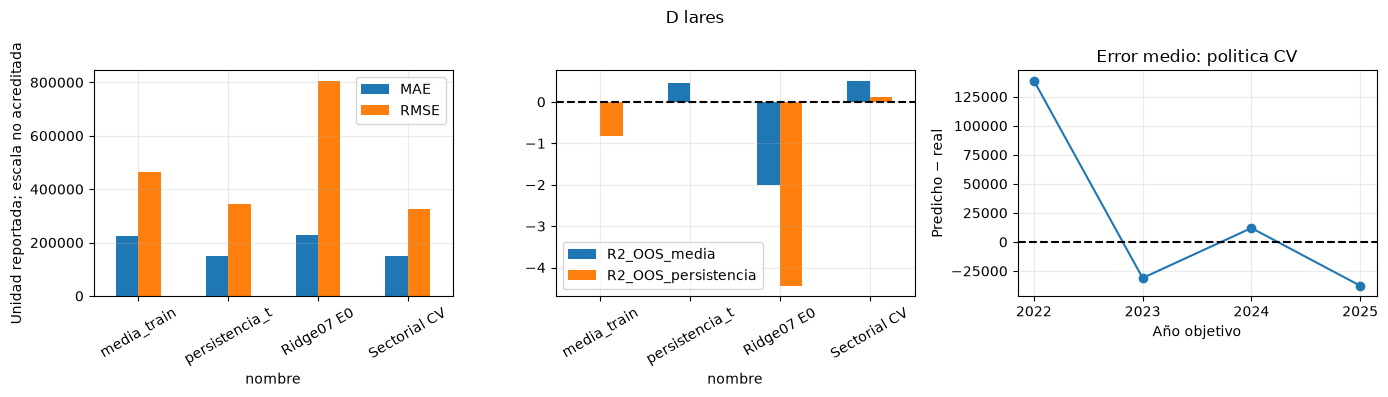

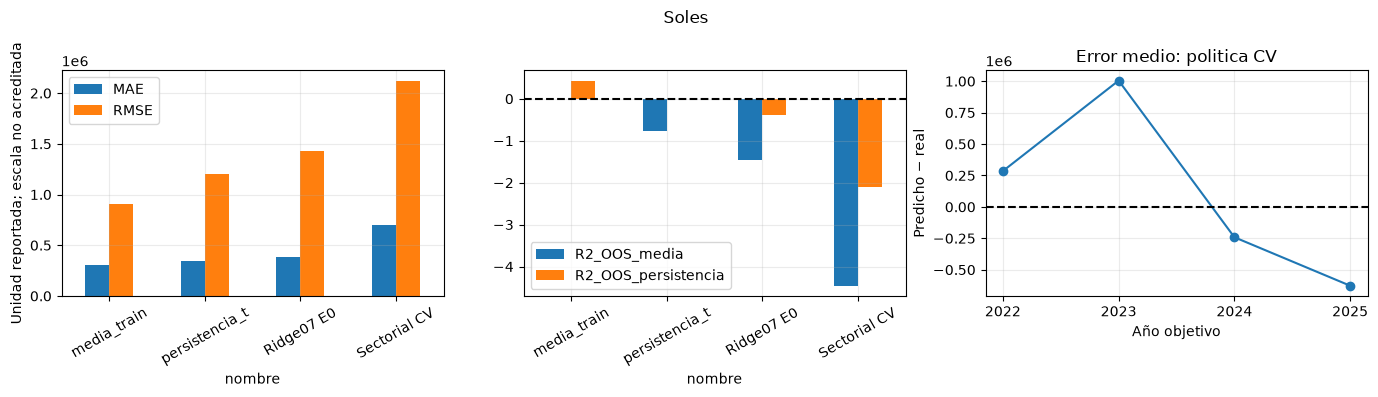

In [13]:
for mo in monedas:
    naive=metricas.loc[metricas.moneda.eq(mo)&metricas.grupo_ajuste.eq("todas")&metricas.especificacion.eq("ingenuo")&metricas.particion.eq("prueba")]
    viejo=anteriores.loc[anteriores.moneda.eq(mo)&anteriores.escenario07.eq("principal")&anteriores.experimento07.eq("E0_financiero")&anteriores.particion.eq("prueba")]
    nuevo=politica.loc[politica.moneda.eq(mo)&politica.particion.eq("prueba")]
    graf=pd.concat([naive.assign(nombre=naive.experimento),viejo.assign(nombre="Ridge07 E0"),nuevo.assign(nombre="Sectorial CV")])
    fig,axs=plt.subplots(1,3,figsize=(14,4))
    graf.set_index("nombre")[["MAE","RMSE"]].plot.bar(ax=axs[0],rot=30);axs[0].set_ylabel("Unidad reportada; escala no acreditada")
    graf.set_index("nombre")[["R2_OOS_media","R2_OOS_persistencia"]].plot.bar(ax=axs[1],rot=30);axs[1].axhline(0,color="black",linestyle="--")
    pp=seleccion_sectorial.loc[seleccion_sectorial.moneda.eq(mo)&seleccion_sectorial.particion.eq("prueba")]
    e=pp.groupby("anio_objetivo").error.mean();axs[2].plot(e.index,e,marker="o");axs[2].axhline(0,color="black",linestyle="--");axs[2].set(title="Error medio: politica CV",xlabel="Año objetivo",ylabel="Predicho − real");axs[2].set_xticks([2022,2023,2024,2025])
    fig.suptitle(mo);fig.tight_layout();plt.show()
metricas_anuales=[]
for (mo,pa,y),g in seleccion_sectorial.groupby(["moneda","particion","anio_objetivo"]):
    refs=referencias[(mo,"todas")].loc[g.id_fila]
    metricas_anuales.append(dict(moneda=mo,particion=pa,anio_objetivo=int(y),**medir(g.y_real,g.y_predicho,refs.media_train,refs.persistencia_t,pa=="prueba")))
metricas_anuales=pd.DataFrame(metricas_anuales)
interpretaciones[13]="Los graficos contrastan la politica elegida solo en CV con ambas referencias ingenuas y con E0 del 07. Se conservan los cuatro años de prueba y todos los errores extremos."
etapas.append(13)

Los graficos contrastan la politica elegida solo en CV con ambas referencias ingenuas y con E0 del 07. Se conservan los cuatro años de prueba y todos los errores extremos.

**14. Verificación de selección, clipping e integridad**

Se comprueba que ningún id de prueba interviene en CV o ajustes finales y se repite un ajuste tras perturbar prueba. La selección congelada, los límites de clipping y las predicciones originales deben permanecer iguales.

In [14]:
ids_test=set(muestra.loc[muestra.particion.eq("prueba"),"id_fila"])
for r in plan:
    assert not ids_test.intersection(r["ids_train"]+r["ids_validacion"])
for a in ajustes:
    assert not ids_test.intersection(a["ids_train"]) and a["n_fit_clipping"]==len(a["ids_train"])
assert hashlib.sha256(seleccion_congelada.to_csv(index=False).encode()).hexdigest()==hash_seleccion
for mo in monedas:
    grupo="no_bancario"
    r=seleccion_congelada.loc[seleccion_congelada.moneda.eq(mo)&seleccion_congelada.grupo.eq(grupo)].iloc[0]
    key=(mo,grupo,r.especificacion,r.experimento);pipe=modelos[key];cols=CONFIGS[(r.especificacion,r.experimento)]
    t=subconjunto(TABLAS[r.especificacion],mo,grupo);tr=t.loc[t.particion.eq("entrenamiento")];te=t.loc[t.particion.eq("prueba")]
    alterado=t.copy();m=alterado.particion.eq("prueba")
    alterado.loc[m,cols]=alterado.loc[m,cols]*100+10000;alterado.loc[m,"objetivo_fcl_t1"]*=100
    pd.testing.assert_frame_equal(alterado.loc[tr.index,cols],tr[cols],check_exact=True)
    p2=clone(pipe).fit(alterado.loc[tr.index,cols],alterado.loc[tr.index,"objetivo_fcl_t1"])
    np.testing.assert_allclose(p2.predict(te[cols]),pipe.predict(te[cols]),rtol=1e-12,atol=1e-8)
    cp1=pipe.named_steps["pre"].named_transformers_["numericas"].named_steps["clip"]
    cp2=p2.named_steps["pre"].named_transformers_["numericas"].named_steps["clip"]
    np.testing.assert_array_equal(cp1.lower_,cp2.lower_);np.testing.assert_array_equal(cp1.upper_,cp2.upper_)
for keys,g in pred.groupby(["moneda","grupo_ajuste","especificacion","experimento"]):
    mo,gr,sp,ex=keys;t=subconjunto(muestra,mo,gr)
    assert set(g.id_fila)==set(t.id_fila)
    np.testing.assert_array_equal(g.set_index("id_fila").loc[t.id_fila,"y_real"],t.objetivo_fcl_t1)
for r in metricas.itertuples(index=False):
    g=pred.loc[pred.moneda.eq(r.moneda)&pred.grupo_ajuste.eq(r.grupo_ajuste)&pred.especificacion.eq(r.especificacion)&pred.experimento.eq(r.experimento)&pred.particion.eq(r.particion)]
    refs=referencias[(r.moneda,r.grupo_ajuste)].loc[g.id_fila]
    sse=np.sum((g.y_predicho-g.y_real)**2)
    np.testing.assert_allclose(r.MAE,np.mean(np.abs(g.y_predicho-g.y_real)),rtol=1e-12)
    np.testing.assert_allclose(r.RMSE,np.sqrt(sse/len(g)),rtol=1e-12)
    if r.particion=="prueba":
        dm=np.sum((g.y_real.to_numpy()-refs.media_train.to_numpy())**2)
        dp=np.sum((g.y_real.to_numpy()-refs.persistencia_t.to_numpy())**2)
        np.testing.assert_allclose(r.R2_OOS_media,1-sse/dm if dm>0 else np.nan,rtol=1e-12,atol=1e-12,equal_nan=True)
        np.testing.assert_allclose(r.R2_OOS_persistencia,1-sse/dp if dp>0 else np.nan,rtol=1e-12,atol=1e-12,equal_nan=True)
assert np.isfinite(pred[["y_real","y_predicho","error"]]).all().all()
assert hashes_previos()==hashes_antes
print("Aprobados: test intacto, folds por año, ajustes train, clipping train, seleccion CV congelada, predicciones finitas y archivos anteriores preservados.")
interpretaciones[14]="La seleccion y los ajustes no utilizan ids de prueba. Al perturbar sus valores y etiquetas, el reajuste conserva limites y predicciones sobre los datos originales; los archivos anteriores permanecen intactos."
etapas.append(14)

Aprobados: test intacto, folds por año, ajustes train, clipping train, seleccion CV congelada, predicciones finitas y archivos anteriores preservados.


La seleccion y los ajustes no utilizan ids de prueba. Al perturbar sus valores y etiquetas, el reajuste conserva limites y predicciones sobre los datos originales; los archivos anteriores permanecen intactos.

**15. Exportación, resumen cuantitativo y límites pendientes**

Se guardan métricas, predicciones, validación temporal, selección y límites de clipping. El resumen distingue mejorar Ridge 07 de superar baselines ingenuos y no presenta la prueba ya auditada como una evaluación independiente nueva.

In [15]:
assert etapas==list(range(1,15))
limitaciones=[
    "FCL es FCO + CAPEX reportado, no FCFF validado; la escala monetaria y el linaje detallado no estan acreditados. No se mezclan monedas.",
    "FCL(t)/FCO(t) verificados algebraicamente, pero sin fecha efectiva de publicacion. Su uso y la persistencia son condicionales a conocer los estados de t; no se certifica backtest point-in-time.",
    "Sin niveles t + externos t-1 es sensibilidad conservadora, no garantia de ausencia de revisiones o rezagos de publicacion de las fuentes financieras.",
    "No bancario incluye seguros, financieras y AFP. Modelar BANCOS por separado no convierte su FCL contable en FCFF industrial valido.",
    "Clipping 1%-99% recorta ratios, no objetivos ni niveles. Se fija por solicitud/auditoria, no por evaluacion de nuevos resultados de prueba.",
    "Hay 16 años de entrenamiento y 8 de validacion en cuatro bloques para cohortes completas; BANCOS tiene 9 años y 4 de validacion en dos bloques; no se asume independencia por empresa ni se afirma significancia estadistica.",
    "La prueba 2022–2025 ya fue analizada por 07 y su auditoria y motivo este rediseño. No se usa para elegir alpha o ganadores, pero no es una prueba virgen para confirmar mejoras; se requiere validacion futura independiente.",
    "La validacion temporal usa orden de años, sin purgado por fechas reales de publicacion porque no existen; las ventanas expansivas no solucionan el problema de vintage.",
    "Se conservan faltantes y filas; FCL(t) no valido se sustituye para persistencia con mediana del FCL(t) valido de entrenamiento, y el Pipeline imputa sus predictores por separado.",
    "La auditoria es orientativa: algunos hashes, etiquetas de escala y cifras citadas no coinciden con los archivos actuales; se recalculan las metricas 07 desde las predicciones, sin copiar sus valores narrativos.",
    "La politica sectorial es una arquitectura predefinida y sus variantes/alphas se eligen por MSE anual de CV; no se sustituye por modelos con mejores metricas de prueba.",
    "Indicadores bursatiles conservan cambio metodologico 2015, discrepancias entre frecuencias y calendario no certificado; externos nominales pueden extrapolar fuera del soporte.",
]
salidas={"metricas_mejoras.csv":metricas,"metricas_baselines_07.csv":anteriores,"comparacion_vs07.csv":comparacion,
    "comparacion_homologa_vs07.csv":homologos,"comparacion_sector_vs07.csv":comparacion_sector,"metricas_sector_07.csv":sector07,"metricas_politica_cv.csv":politica,"metricas_por_anio.csv":metricas_anuales,
    "metricas_agrupados_por_sector.csv":desglose_sector,"predicciones_mejoras.csv":pred,
    "predicciones_seleccionadas_cv.csv":seleccion_sectorial,"cv_folds.csv":cv,"cv_por_anio.csv":cv_anios,
    "cv_puntuaciones.csv":puntuaciones,"alphas_optimos.csv":optimos,"seleccion_congelada_cv.csv":seleccion_congelada,
    "umbrales_clipping.csv":umbrales,"parametros_ingenuos.csv":param_naive,"conteos_muestra.csv":conteos.reset_index()}
inventario={}
for name,t in salidas.items():
    path=OUT/name;t.to_csv(path,index=False,encoding="utf-8",na_rep="")
    inventario[name]={"filas":len(t),"columnas":t.shape[1],"sha256":hashlib.sha256(path.read_bytes()).hexdigest()}
pp=pd.read_csv(OUT/"predicciones_mejoras.csv",dtype={"RPJ":"string","RUC":"string"},float_precision="round_trip")
pd.testing.assert_frame_equal(pp,pred,check_exact=True,check_dtype=False)
mm=pd.read_csv(OUT/"metricas_mejoras.csv",float_precision="round_trip")
pd.testing.assert_frame_equal(mm,metricas,check_exact=True,check_dtype=False)
lineas=["Mejoras del Baseline: evaluacion condicional retrospectiva","", "Muestra inalterada: 3560 casos elegibles, 2869 entrenamiento y 691 prueba. Soles y dolares se modelan por separado.",
    "Clipping p1/p99 por fold; alpha 0.1–10000 con cuatro ventanas expansivas por años objetivo (dos para BANCOS por cobertura limitada). Seleccion final solo por MSE anual de validacion.","", "Politica sectorial seleccionada antes de evaluar prueba:","", "Moneda | n | MAE | RMSE | R2 | R2 OOS media | R2 OOS persistencia","--- | --- | --- | --- | --- | --- | ---"]
for r in politica.loc[politica.particion.eq("prueba")].itertuples():lineas.append(f"{r.moneda} | {r.n} | {r.MAE:.4f} | {r.RMSE:.4f} | {r.R2:.6f} | {r.R2_OOS_media:.6f} | {r.R2_OOS_persistencia:.6f}")
lineas += ["", "Ganadores por cohorte decididos en CV:"]
for r in seleccion_congelada.itertuples():lineas.append(f"{r.moneda}/{r.grupo}: {r.especificacion}, {r.experimento}, alpha={r.alpha:g}; RMSE CV anual={r.rmse_cv:.4f}.")
lineas += ["", "Comparacion con E0 del 07:"]
for r in comparacion.loc[comparacion.particion.eq("prueba")].itertuples():lineas.append(f"{r.moneda}: MAE {describir_cambio(r.mejora_MAE_vs07_pct)}, RMSE {describir_cambio(r.mejora_RMSE_vs07_pct)}.")
lineas += ["", "Un R2 OOS negativo significa no superar la referencia ingenua en SSE, aunque se reduzca el error respecto a Ridge 07.",
    "El modelo elegido para BANCOS por CV empeora en prueba; no se reemplaza usando sus metricas. Las mejoras no son universales y debe conservarse esta evidencia negativa.",
    "Pendiente: escala monetaria, publicacion/vintages, validez del FCL bancario y evaluacion independiente futura. La prueba actual ya fue inspeccionada al motivar estas mejoras; no se usa para elegir modelos."]
(OUT/"resumen_mejoras.md").write_text("\n".join(lineas)+"\n",encoding="utf-8")
assert hashes_previos()==hashes_antes
def seguro(x):
    if isinstance(x,dict):return {str(k):seguro(v) for k,v in x.items()}
    if isinstance(x,(list,tuple)):return [seguro(v) for v in x]
    if isinstance(x,np.generic):return seguro(x.item())
    if isinstance(x,float) and not np.isfinite(x):return None
    return x
validacion={"estado":"EJECUTADO_CON_LIMITACIONES","fecha_utc":datetime.now(timezone.utc).isoformat(),"python":platform.python_version(),"versiones":versiones,
    "semilla":SEED,"observaciones":len(muestra),"empresas_elegibles":muestra.RPJ.nunique(),"particiones":muestra.particion.value_counts().to_dict(),
    "n_modelos_ridge":len(modelos),"n_predicciones":len(pred),"cv_alpha":ALPHAS,"clipping_cuantiles":[Q_INF,Q_SUP],"ratios_recortados":RATIOS,
    "cohortes":cohortes,"configuraciones":[{"especificacion":s,"experimento":e,"predictores":cols} for (s,e),cols in CONFIGS.items()],
    "cv_criterio":"MSE medio de años unicos de validacion; empate favorece mayor alpha, despues orden lexical fijo",
    "pliegues":plan,"configuraciones_seleccionadas_cv":seleccion_congelada.to_dict(orient="records"),"hash_seleccion":hash_seleccion,
    "ajustes_finales":ajustes,"resultados_politica":politica.to_dict(orient="records"),"comparacion_vs07":comparacion.to_dict(orient="records"),
    "controles":{"test_691_originales":True,"sin_eliminacion_de_filas":True,"objetivo_y_monedas_preservados":True,"cv_por_anios_no_filas":True,
        "ningun_id_test_en_cv_o_fit":True,"clipping_imputacion_escala_solo_train":True,"alpha_seleccionado_sin_test":True,
        "ganadores_congelados_antes_de_test":True,"perturbacion_test_invariante":True,"predicciones_finitas":True,"metricas_07_recalculadas":True,
        "relectura_exacta":True,"archivos_anteriores_preservados":True},
    "niveles_contemporaneos":{"FCL_t_verificado":"FCO(t)+CAPEX(t), invalido si CAPEX>0; inclusion explicita solicitada, no automatica por rol de fuente",
        "FCO_t":"Copia de FCO(t); inclusion explicita solicitada", "fecha_publicacion":"NO_VERIFICADA; modelos condicionales, no operativos certificados"},
    "disponibilidad_temporal_real":"NO_VERIFICADA","prueba_independiente_del_rediseño":False,"limitaciones":limitaciones,
    "archivos_previos":hashes_antes,"inventario":inventario,"interpretaciones":interpretaciones,
    "ejecucion":{"bloques_codigo":15,"bloques_previos_completados":etapas.copy()}}
(OUT/"validacion_mejoras.json").write_text(json.dumps(seguro(validacion),ensure_ascii=False,indent=2,allow_nan=False)+"\n",encoding="utf-8")
print("Reportes:",OUT.relative_to(ROOT),"| Prueba:",len(seleccion_sectorial.loc[seleccion_sectorial.particion.eq("prueba")]))
print("Seleccion exclusivamente por CV; originales y notebook 07 intactos.")
etapas.append(15)

Reportes: reports/sprint_06/mejoras | Prueba: 691
Seleccion exclusivamente por CV; originales y notebook 07 intactos.


Las métricas, predicciones, selección CV y límites quedan exportados con sus controles. Persisten límites de publicación, escala y validez del FCL bancario; una mejora en la prueba ya auditada requiere confirmación independiente.